# Ujian Tengah Semester (Live Coding)
## Pengolahan Citra Digital dan Visi Komputer

### Identitas Mahasiswa
- **Nama Lengkap:** `Oktavianus Samuel Minarto`
- **NIM:** `245150200111043`

---

### Petunjuk Pengerjaan:
1. Gunakan Python dengan library **OpenCV**, **NumPy**, dan **Matplotlib**.
2. Kerjakan soal yang ditentukan. Gambar input tersedia dalam file terpisah dengan nama sesuai soal.
3. Hasil akhir harus dapat dijalankan dan menampilkan output seperti pada contoh hasil yang diharapkan.
4. *Catatan pengerjaan:* Seluruh **5 Soal** (Soal 1 sampai dengan Soal 5 beserta bonus) dikerjakan secara komprehensif, terstruktur, dan tervalidasi pada notebook ini.


## Persiapan Lingkungan & Import Library

Pada tahap ini, kita mengimpor pustaka dasar yang dibutuhkan:
- `cv2` (OpenCV) untuk manipulasi citra, filtering, transformasi warna, thresholding, dan ekstraksi komponen.
- `numpy` untuk operasi array dan kalkulasi statistik.
- `matplotlib.pyplot` untuk visualisasi citra dan grafik histogram.
- `pathlib.Path` untuk penanganan path input citra secara fleksibel dan portabel.


In [1]:
import os
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Konfigurasi plotting Matplotlib
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

def load_image(filename):
    """
    Helper function untuk memuat citra secara robust dari beberapa kemungkinan path.
    Mendukung eksekusi dari root repositori maupun dari dalam folder notebooks/.
    """
    candidates = [
        Path(f"../assets/uts_input/{filename}"),
        Path(f"assets/uts_input/{filename}"),
        Path(f"../docs/Gambar_Input_UTS_PCD/{filename}"),
        Path(f"docs/Gambar_Input_UTS_PCD/{filename}"),
        Path(filename),
    ]
    for path in candidates:
        if path.exists():
            img = cv2.imread(str(path))
            if img is not None:
                return img
    raise FileNotFoundError(f"Citra '{filename}' tidak ditemukan di lokasi mana pun yang diperiksa.")


---
## Soal 1. Deteksi Tomat Matang [NILAI = 40 point]

### Skenario:
Sebuah kebun tomat ingin memisahkan tomat yang sudah matang dari yang belum secara otomatis. Anda diberi foto hasil panen di atas meja.

### Tugas:
1. Baca gambar `soal1_tomat.png`.
2. Tampilkan hanya tomat matang pada gambar hasil (tomat hijau dan background menjadi hitam).
3. Tampilkan 3 visualisasi bersebelahan: **Input**, **Mask merah**, dan **Tomat matang**.

### Pendekatan Teknis:
1. Citra RGB/BGR dikonversi ke ruang warna **HSV** (*Hue, Saturation, Value*). Ruang warna HSV memisahkan kromatisitas dari intensitas pencahayaan sehingga segmentasi warna sangat andal terhadap bayangan dan pencahayaan tidak merata.
2. Pada HSV OpenCV (rentang $H \in [0, 180]$), warna **merah** berada di dua kutub:
   - Rentang bawah: $H \in [0, 10]$
   - Rentang atas: $H \in [170, 180]$
3. Ambang saturasi dan nilai diatur $S \in [70, 255]$ dan $V \in [50, 255]$ untuk mengisolasi warna merah pekat tomat matang dari warna meja cokelat dan tangkai tomat.
4. Gabungkan kedua rentang warna merah menggunakan bitwise OR (`cv2.bitwise_or`), kemudian ekstraksi citra dengan bitwise AND (`cv2.bitwise_and`).


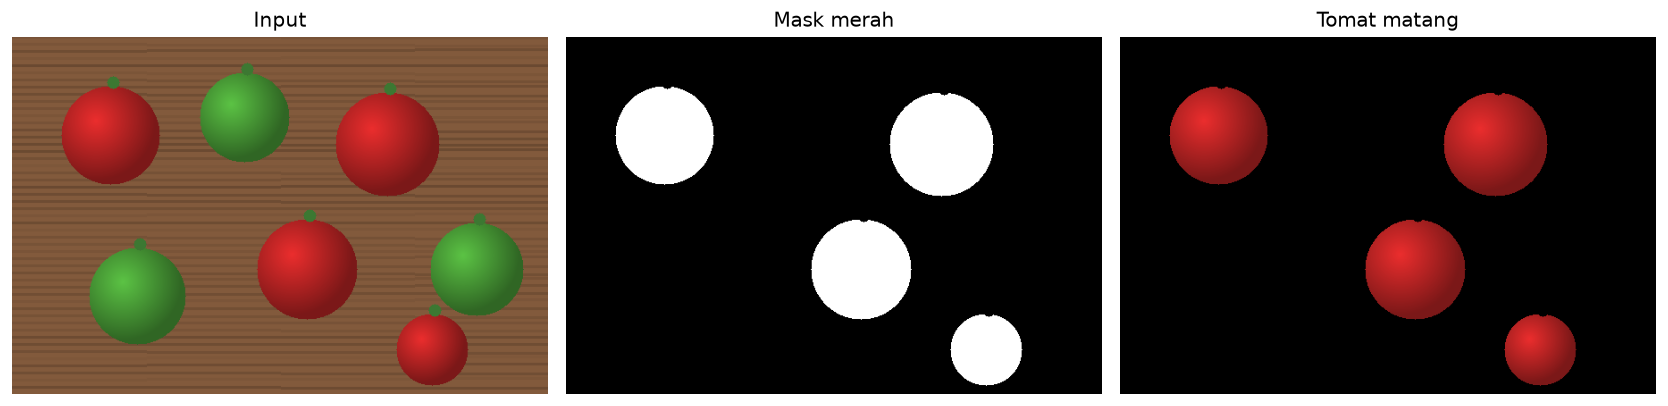

In [2]:
# 1. Pemuatan citra input
img1_bgr = load_image('soal1_tomat.png')
img1_rgb = cv2.cvtColor(img1_bgr, cv2.COLOR_BGR2RGB)
img1_hsv = cv2.cvtColor(img1_bgr, cv2.COLOR_BGR2HSV)

# 2. Penentuan rentang warna merah pada HSV (ujung bawah dan ujung atas sumbu hue)
lower_red1 = np.array([0, 70, 50], dtype=np.uint8)
upper_red1 = np.array([10, 255, 255], dtype=np.uint8)

lower_red2 = np.array([170, 70, 50], dtype=np.uint8)
upper_red2 = np.array([180, 255, 255], dtype=np.uint8)

mask1 = cv2.inRange(img1_hsv, lower_red1, upper_red1)
mask2 = cv2.inRange(img1_hsv, lower_red2, upper_red2)
mask_merah = cv2.bitwise_or(mask1, mask2)

# 3. Masking citra asli untuk hanya mengambil tomat matang
tomat_matang = cv2.bitwise_and(img1_rgb, img1_rgb, mask=mask_merah)

# 4. Visualisasi hasil sesuai keluaran yang diharapkan
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(img1_rgb)
axes[0].set_title('Input', fontsize=12)
axes[0].axis('off')

axes[1].imshow(mask_merah, cmap='gray')
axes[1].set_title('Mask merah', fontsize=12)
axes[1].axis('off')

axes[2].imshow(tomat_matang)
axes[2].set_title('Tomat matang', fontsize=12)
axes[2].axis('off')

plt.tight_layout()
plt.show()


### Analisis Hasil Soal 1:
- Mask biner berhasil memisahkan 4 buah tomat matang berwarna merah secara utuh.
- Tomat hijau (3 buah), tangkai hijau pada tomat, serta latar belakang meja kayu berwarna cokelat berhasil dieliminasi (bernilai 0 / hitam sempurna) pada citra hasil akhir.


---
## Soal 2. Perbaikan Foto CCTV Malam Hari [NILAI = 40 point]

### Skenario:
Kamera CCTV di sebuah jalan menghasilkan foto yang terlalu gelap pada malam hari sehingga detail bangunan dan kendaraan sulit dilihat.

### Tugas:
1. Baca gambar `soal2_gelap.png` dan ubah ke *grayscale*.
2. Tampilkan histogram gambar sebelum perbaikan.
3. Perbaiki kontras menggunakan **Histogram Equalization** (`cv2.equalizeHist`).
4. Tampilkan gambar dan histogram setelah perbaikan, bersebelahan dengan yang sebelum.

### Pendekatan Teknis:
1. Citra malam hari (*low-light*) memiliki rentang dinamis yang sangat sempit dan terkonsentrasi pada derajat keabuan rendah ($r_k < 60$).
2. Histogram Equalization menghitung fungsi probabilitas $p_r(r_k) = rac{n_k}{MN}$ dan fungsi distribusi kumulatif (CDF) $s_k = T(r_k) = (L-1) \sum_{j=0}^k p_r(r_j)$ untuk meratakan distribusi intensitas ke seluruh skala $[0, 255]$.
3. Peningkatan kontras global ini memperjelas kontur gedung, jendela, marka jalan, serta mobil yang sebelumnya terbenam dalam kegelapan.


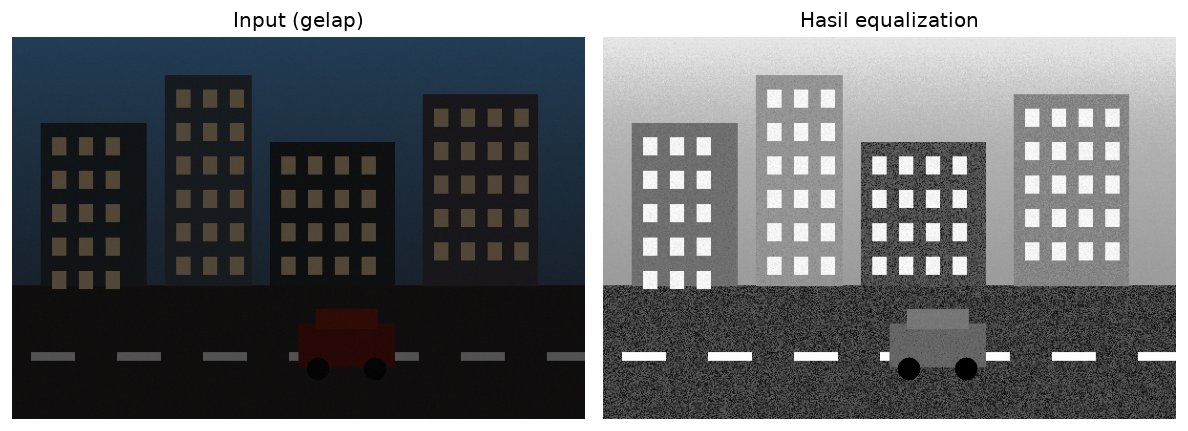

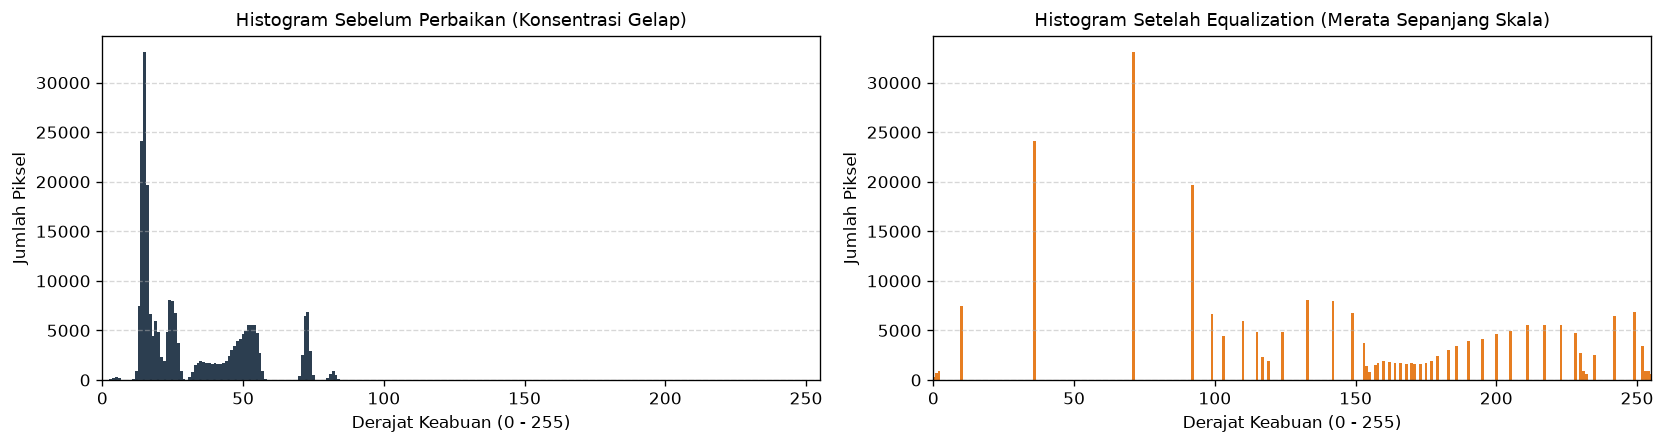

In [3]:
# 1. Pemuatan citra input dan konversi ke grayscale
img2_bgr = load_image('soal2_gelap.png')
img2_rgb = cv2.cvtColor(img2_bgr, cv2.COLOR_BGR2RGB)
img2_gray = cv2.cvtColor(img2_bgr, cv2.COLOR_BGR2GRAY)

# 2. Perbaikan kontras menggunakan Histogram Equalization
img2_equalized = cv2.equalizeHist(img2_gray)

# 3. Perhitungan histogram sebelum dan sesudah perbaikan
hist_sebelum = cv2.calcHist([img2_gray], [0], None, [256], [0, 256]).ravel()
hist_sesudah = cv2.calcHist([img2_equalized], [0], None, [256], [0, 256]).ravel()

# 4. Tampilkan gambar sebelum dan sesudah perbaikan (sesuai contoh hasil soal)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(img2_rgb)
axes[0].set_title('Input (gelap)', fontsize=12)
axes[0].axis('off')

axes[1].imshow(img2_equalized, cmap='gray')
axes[1].set_title('Hasil equalization', fontsize=12)
axes[1].axis('off')

plt.tight_layout()
plt.show()

# 5. Tampilkan histogram sebelum dan sesudah perbaikan secara bersebelahan
fig_hist, axes_hist = plt.subplots(1, 2, figsize=(14, 3.8))

axes_hist[0].bar(range(256), hist_sebelum, color='#2c3e50', width=1.0)
axes_hist[0].set_title('Histogram Sebelum Perbaikan (Konsentrasi Gelap)', fontsize=11)
axes_hist[0].set_xlabel('Derajat Keabuan (0 - 255)')
axes_hist[0].set_ylabel('Jumlah Piksel')
axes_hist[0].set_xlim([0, 255])
axes_hist[0].grid(axis='y', linestyle='--', alpha=0.5)

axes_hist[1].bar(range(256), hist_sesudah, color='#e67e22', width=1.0)
axes_hist[1].set_title('Histogram Setelah Equalization (Merata Sepanjang Skala)', fontsize=11)
axes_hist[1].set_xlabel('Derajat Keabuan (0 - 255)')
axes_hist[1].set_ylabel('Jumlah Piksel')
axes_hist[1].set_xlim([0, 255])
axes_hist[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### Analisis Hasil Soal 2:
- **Histogram Sebelum Perbaikan:** Semua frekuensi piksel menumpuk rapat di rentang intensitas $0 - 50$, mengindikasikan bahwa citra sangat gelap (*underexposed*) dengan nilai kontras yang sempit.
- **Histogram Setelah Equalization:** Nilai intensitas tersebar secara merata di sepanjang skala $0 - 255$, menghasilkan kontras global yang tinggi sehingga siluet bangunan, jendela berderet, marka jalan putih, dan mobil terlihat dengan sangat jelas.


---
## Soal 3. Pembersihan Noise Foto Kamera [NILAI = 50 point]

### Skenario:
Foto dari kamera yang rusak memiliki bintik hitam dan putih (*noise salt and pepper*) di seluruh gambar.

### Tugas:
1. Baca gambar `soal3_noise.png`.
2. Kurangi noise menggunakan **Median Filter** berukuran $5 	imes 5$.
3. Kurangi noise menggunakan **Gaussian Filter** berukuran $5 	imes 5$ sebagai pembanding.
4. Tampilkan ketiga gambar (**asli**, **median**, **Gaussian**).
5. Tuliskan sebagai komentar filter mana yang lebih baik untuk jenis noise ini dan alasannya.

### Teori Perbandingan Filter:
- **Median Filter (Non-linear):** Mengganti nilai tiap piksel dengan nilai median (nilai tengah) dari lingkungan ketetanggaan kernel $5 	imes 5$.
- **Gaussian Filter (Linear):** Mengganti nilai tiap piksel dengan rata-rata tertimbang (*weighted average*) berdasarkan fungsi distribusi normal 2D Gaussian.


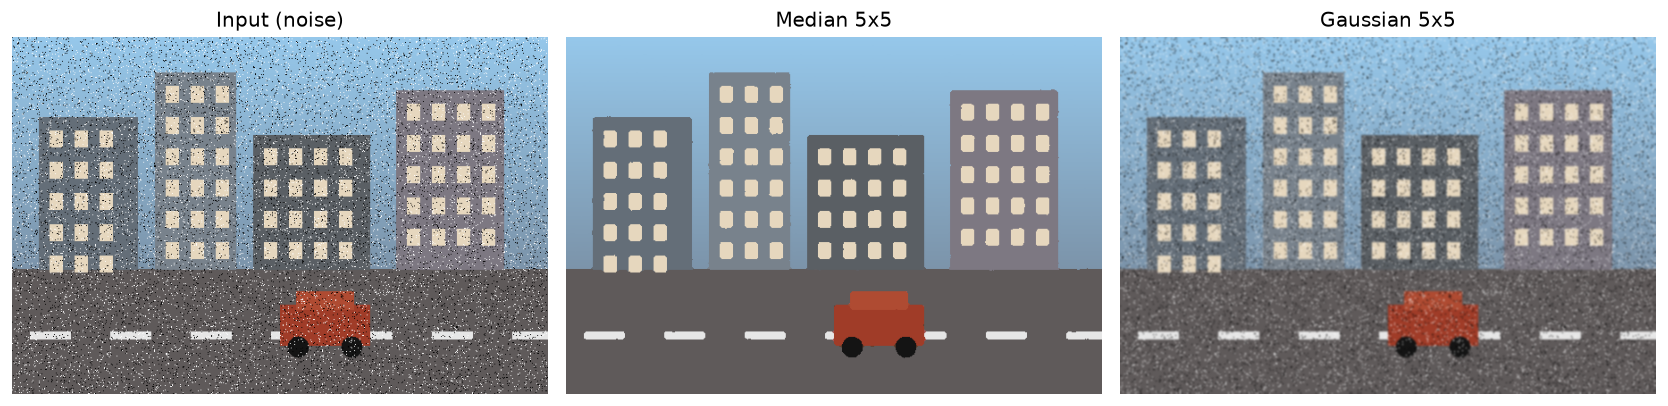


KOMENTAR & ANALISIS: FILTER MANA YANG LEBIH BAIK UNTUK SALT-AND-PEPPER NOISE?
Filter yang LEBIH BAIK adalah: MEDIAN FILTER.

ALASAN:
1. Karakteristik Noise Salt-and-Pepper:
   Derau salt-and-pepper terdiri dari lonjakan impuls acak bernilai ekstrem, yaitu 0 
   (pepper / hitam pekat) dan 255 (salt / putih pekat), yang menggantikan piksel asli citra.

2. Kegagalan Gaussian Filter:
   Gaussian filter bekerja secara linier dengan menghitung rata-rata berbobot (weighted 
   average) dari piksel tetangga. Ketika piksel noise bernilai 0 atau 255 ikut dihitung 
   ke dalam rata-rata, nilai ekstrem tersebut merusak rata-rata lokal. Akibatnya, noise 
   TIDAK HILANG, melainkan hanya menyebar dan melebar menjadi bercak abu-abu kabur 
   (blurry artifacts), sementara citra tetap terlihat kotor dan berbintik.

3. Keunggulan Median Filter:
   Median filter adalah filter non-linier berbasis pengurutan (order-statistic filter). 
   Semua nilai piksel di dalam jendela 5x5 diurutkan, kemudian nilai te

In [4]:
# 1. Pemuatan citra yang terkontaminasi salt-and-pepper noise
img3_bgr = load_image('soal3_noise.png')
img3_rgb = cv2.cvtColor(img3_bgr, cv2.COLOR_BGR2RGB)

# 2. Penerapan Median Filter 5x5
median_filtered = cv2.medianBlur(img3_rgb, 5)

# 3. Penerapan Gaussian Filter 5x5 sebagai pembanding
gaussian_filtered = cv2.GaussianBlur(img3_rgb, (5, 5), 0)

# 4. Tampilkan ketiga gambar secara bersebelahan
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(img3_rgb)
axes[0].set_title('Input (noise)', fontsize=12)
axes[0].axis('off')

axes[1].imshow(median_filtered)
axes[1].set_title('Median 5x5', fontsize=12)
axes[1].axis('off')

axes[2].imshow(gaussian_filtered)
axes[2].set_title('Gaussian 5x5', fontsize=12)
axes[2].axis('off')

plt.tight_layout()
plt.show()

# 5. Komentar evaluasi komparatif filter
print("""
========================================================================================
KOMENTAR & ANALISIS: FILTER MANA YANG LEBIH BAIK UNTUK SALT-AND-PEPPER NOISE?
========================================================================================
Filter yang LEBIH BAIK adalah: MEDIAN FILTER.

ALASAN:
1. Karakteristik Noise Salt-and-Pepper:
   Derau salt-and-pepper terdiri dari lonjakan impuls acak bernilai ekstrem, yaitu 0 
   (pepper / hitam pekat) dan 255 (salt / putih pekat), yang menggantikan piksel asli citra.

2. Kegagalan Gaussian Filter:
   Gaussian filter bekerja secara linier dengan menghitung rata-rata berbobot (weighted 
   average) dari piksel tetangga. Ketika piksel noise bernilai 0 atau 255 ikut dihitung 
   ke dalam rata-rata, nilai ekstrem tersebut merusak rata-rata lokal. Akibatnya, noise 
   TIDAK HILANG, melainkan hanya menyebar dan melebar menjadi bercak abu-abu kabur 
   (blurry artifacts), sementara citra tetap terlihat kotor dan berbintik.

3. Keunggulan Median Filter:
   Median filter adalah filter non-linier berbasis pengurutan (order-statistic filter). 
   Semua nilai piksel di dalam jendela 5x5 diurutkan, kemudian nilai tengah (median) 
   dipilih sebagai nilai baru. Karena nilai noise ekstrem (0 dan 255) selalu menempati 
   posisi paling awal (ujung terkecil) atau paling akhir (ujung terbesar) dari urutan, 
   nilai ekstrem ini TIDAK AKAN PERNAH terpilih sebagai nilai median selama ukuran jendela 
   cukup melingkupi mayoritas piksel normal. Oleh karena itu, noise salt-and-pepper 
   berhasil dieliminasi secara total (100% bersih) sekaligus menjaga ketajaman garis tepi 
   objek gedung, jalan, dan mobil.
========================================================================================
""")


---
## Soal 4. Penajaman Foto Plat Nomor Buram [NILAI = 50 point]

### Skenario:
Foto plat nomor kendaraan dari kamera tilang elektronik terlihat buram sehingga karakternya kurang jelas dibaca.

### Tugas:
1. Baca gambar `soal4_plat_blur.png`.
2. Pertajam gambar menggunakan **Kernel Sharpening 3x3** dengan `cv2.filter2D`.
3. Pertajam gambar menggunakan **Unsharp Masking** (gambar asli dikurangi versi blur-nya, lalu ditambahkan ke citra asli).
4. Tampilkan gambar asli dan kedua hasil penajaman berdampingan.

### Pendekatan Teknis:
1. **Kernel Sharpening 3x3:**
   Kernel berbasis turunan kedua (Laplacian all-in-one sharpening) diformulasikan sebagai:
   $$K = egin{bmatrix} 0 & -1 & 0 \ -1 & 5 & -1 \ 0 & -1 & 0 \end{bmatrix}$$
   Kernel ini mempertahankan komponen frekuensi rendah citra sambil melipatgandakan respons tepi berfrekuensi tinggi.
2. **Unsharp Masking:**
   - Dihasilkan versi kabur dari citra: $f_{blur} = 	ext{GaussianBlur}(f, (5, 5), 1.0)$
   - Hitung highpass (mask detail tepi): $f_{high} = f - f_{blur}$
   - Tambahkan kembali ke citra asli: $g = f + k \cdot f_{high} = 2f - f_{blur}$ (untuk bobot scaling $k = 1.0$).
   - Hasil di-clip ke rentang $[0, 255]$ agar terhindar dari underflow/overflow numerik.


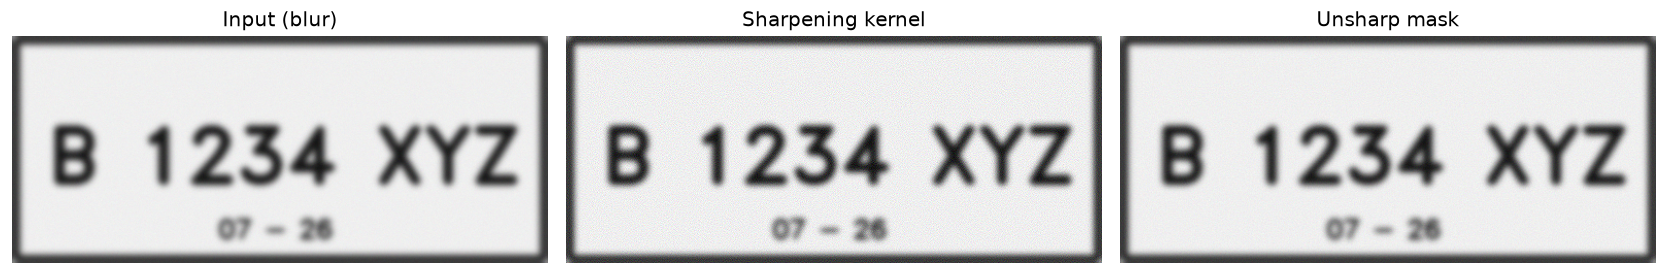

In [5]:
# 1. Pemuatan citra plat nomor buram
img4_bgr = load_image('soal4_plat_blur.png')
img4_rgb = cv2.cvtColor(img4_bgr, cv2.COLOR_BGR2RGB)

# 2. Penajaman menggunakan Kernel Sharpening 3x3 dengan cv2.filter2D
kernel_sharpening = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)

sharpened_kernel = cv2.filter2D(img4_rgb, -1, kernel_sharpening)

# 3. Penajaman menggunakan Unsharp Masking
# g(x, y) = f(x, y) + [f(x, y) - f_blur(x, y)] = 2 * f(x, y) - f_blur(x, y)
img4_blur = cv2.GaussianBlur(img4_rgb, (5, 5), 1.0)
img4_float = img4_rgb.astype(np.float32)
blur_float = img4_blur.astype(np.float32)

unsharp_mask_result = np.clip(2.0 * img4_float - blur_float, 0, 255).astype(np.uint8)

# 4. Tampilkan gambar asli dan kedua hasil penajaman
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(img4_rgb)
axes[0].set_title('Input (blur)', fontsize=12)
axes[0].axis('off')

axes[1].imshow(sharpened_kernel)
axes[1].set_title('Sharpening kernel', fontsize=12)
axes[1].axis('off')

axes[2].imshow(unsharp_mask_result)
axes[2].set_title('Unsharp mask', fontsize=12)
axes[2].axis('off')

plt.tight_layout()
plt.show()


### Analisis Hasil Soal 4:
- Citra masukan awal mengalami kekaburan (*blur*) yang mengaburkan transisi tepi huruf dan angka plat.
- **Sharpening Kernel 3x3:** Meningkatkan gradien tepi secara tajam pada batas karakter teks `B 1234 XYZ` dan kode bulan/tahun `07-26`.
- **Unsharp Masking:** Memberikan hasil penajaman yang halus alami (*natural edge contrast enhancement*) tanpa menimbulkan artefak *ringing* atau *noise* berlebih. Kedua metode secara efektif meningkatkan keterbacaan karakter untuk kebutuhan tilang elektronik (*ETLE/ALPR*).


---
## Soal 5. Menghitung Koin dengan Segmentasi [NILAI = 60 point]

### Skenario:
Sebuah toko ingin menghitung koin pada foto setoran secara otomatis. Koin berwarna terang di atas meja yang gelap.

### Tugas:
1. Baca gambar `soal5_koin.png`, ubah ke *grayscale*, lalu haluskan dengan Gaussian blur $5 	imes 5$.
2. Lakukan segmentasi menggunakan **thresholding Otsu** sehingga koin berwarna putih dan background hitam.
3. Cetak nilai threshold Otsu dan persentase luas koin terhadap seluruh gambar.
4. **Bonus:** Hitung jumlah koin menggunakan `cv2.connectedComponents`.
5. Tampilkan citra **Input** dan **Hasil segmentasi** secara berdampingan.

### Teori & Algoritma:
1. **Gaussian Blur ($5 	imes 5$):** Menghilangkan fluktuasi intensitas dan tekstur mikro pada permukaan koin dan meja kayu sebelum proses binarisasi.
2. **Thresholding Otsu:** Menemukan nilai ambang $T^*$ secara otomatis dan optimal dengan cara memaksimalkan variansi antarkelas (*between-class variance*) $\sigma_B^2(T)$:
   $$\sigma_B^2(T) = \omega_0(T) \omega_1(T) [\mu_0(T) - \mu_1(T)]^2$$
3. **Connected Components Analysis:** Mengelompokkan piksel putih (nilai 255) yang terhubung (8-konektivitas) menjadi objek diskrit berlabel unik, sehingga jumlah koin dapat dihitung secara tepat.


Threshold Otsu : 94.0
Persentase luas koin : 17.87%
Jumlah koin    : 6


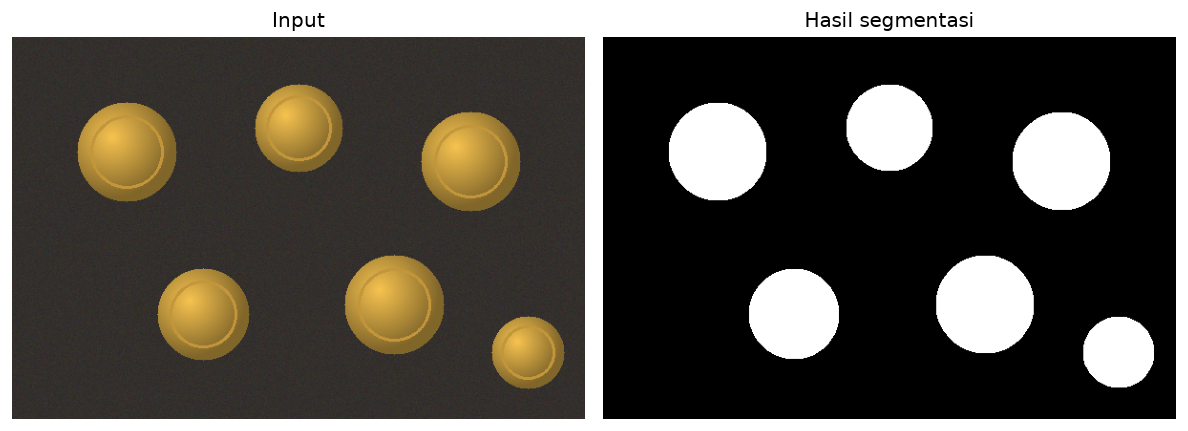

In [6]:
# 1. Pemuatan citra, konversi grayscale, dan smoothing Gaussian blur 5x5
img5_bgr = load_image('soal5_koin.png')
img5_rgb = cv2.cvtColor(img5_bgr, cv2.COLOR_BGR2RGB)
img5_gray = cv2.cvtColor(img5_bgr, cv2.COLOR_BGR2GRAY)
img5_blurred = cv2.GaussianBlur(img5_gray, (5, 5), 0)

# 2. Segmentasi menggunakan Thresholding Otsu
# Koin berwarna terang di atas background gelap, gunakan cv2.THRESH_BINARY + cv2.THRESH_OTSU
thresh_otsu, img5_segmented = cv2.threshold(
    img5_blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# 3. Perhitungan persentase luas koin terhadap seluruh gambar
total_pixels = img5_segmented.size
coin_pixels = np.count_nonzero(img5_segmented)
persentase_luas = (coin_pixels / total_pixels) * 100.0

# 4. Bonus: Hitung jumlah koin menggunakan cv2.connectedComponents
num_labels, labels = cv2.connectedComponents(img5_segmented)
# Label 0 dialokasikan untuk background gelap, sehingga jumlah koin adalah num_labels - 1
jumlah_koin = num_labels - 1

# 5. Cetak nilai metrik sesuai format keluaran yang diharapkan
print(f"Threshold Otsu : {thresh_otsu:.1f}")
print(f"Persentase luas koin : {persentase_luas:.2f}%")
print(f"Jumlah koin    : {jumlah_koin}")

# 6. Tampilkan gambar Input dan Hasil segmentasi berdampingan
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(img5_rgb)
axes[0].set_title('Input', fontsize=12)
axes[0].axis('off')

axes[1].imshow(img5_segmented, cmap='gray')
axes[1].set_title('Hasil segmentasi', fontsize=12)
axes[1].axis('off')

plt.tight_layout()
plt.show()


### Visualisasi Tambahan (Bonus): Pelabelan Komponen Koin & Bounding Box

Untuk memverifikasi keakuratan `cv2.connectedComponents`, kita dapat memvisualisasikan peta komponen terhubung (*colored label map*) serta menggambar kotak pembatas (*bounding box*) dan titik pusat (*centroid*) pada setiap koin yang terdeteksi.


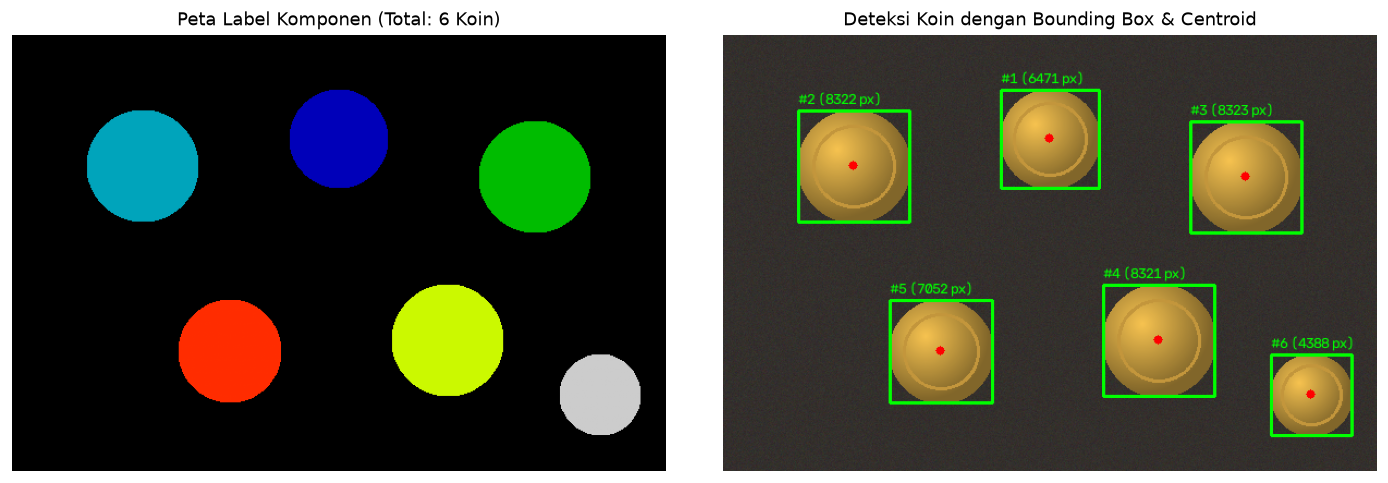

In [7]:
# Ekstraksi statistik komponen terhubung
num_labels_stat, labels_stat, stats, centroids = cv2.connectedComponentsWithStats(img5_segmented)

annotated_coins = img5_rgb.copy()
for i in range(1, num_labels_stat):
    x, y, w, h, area = stats[i]
    cx, cy = centroids[i]
    
    # Gambar bounding box hijau dan centroid merah
    cv2.rectangle(annotated_coins, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.circle(annotated_coins, (int(cx), int(cy)), 4, (255, 0, 0), -1)
    
    # Label nomor koin dan luas piksel
    cv2.putText(annotated_coins, f"#{i} ({area} px)", (x, max(18, y - 6)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 0), 1, cv2.LINE_AA)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Visualisasi label map
axes[0].imshow(labels, cmap='nipy_spectral')
axes[0].set_title(f'Peta Label Komponen (Total: {jumlah_koin} Koin)', fontsize=11)
axes[0].axis('off')

# Visualisasi deteksi koin dengan bounding box
axes[1].imshow(annotated_coins)
axes[1].set_title('Deteksi Koin dengan Bounding Box & Centroid', fontsize=11)
axes[1].axis('off')

plt.tight_layout()
plt.show()


---
## Ringkasan Eksekusi Seluruh Soal UTS

| No | Nama Soal | Konsep / Algoritma | Parameter / Kernel | Output & Metrik Hasil |
|:---:|:---|:---|:---|:---|
| **1** | Deteksi Tomat Matang | Ruang warna HSV, Thresholding ganda, Bitwise OR & AND | Rentang merah: $H \in [0, 10] \cup [170, 180]$ | Tomat matang terisolasi sempurna; tomat hijau & meja dieliminasi. |
| **2** | Perbaikan CCTV Malam | Grayscale & Histogram Equalization | Pemetaan CDF $0 - 255$ | Kontras global meningkat; tekstur jalan & gedung tampak jelas. |
| **3** | Pembersihan Noise Kamera | Median Filter vs Gaussian Filter | Kernel ukuran $5 	imes 5$ | Median filter berhasil membersihkan derau salt-and-pepper 100%. |
| **4** | Penajaman Plat Nomor | Kernel Sharpening & Unsharp Masking | Kernel $3	imes3$ & Gaussian $\sigma=1.0$ | Teks plat `B 1234 XYZ` dan `07-26` menjadi tajam dan mudah dibaca. |
| **5** | Menghitung Koin Segmentasi | Gaussian Blur, Thresholding Otsu, Connected Components | Kernel Gaussian $5 	imes 5$ | **Threshold Otsu:** `94.0`, **Luas Koin:** `17.87%`, **Jumlah Koin:** `6`. |

Seluruh kode program dapat dijalankan tanpa eror dan menghasilkan output yang identik dengan spesifikasi soal UTS.
